In [30]:
%pip install  opencv-python

In [31]:
import matplotlib.pyplot as plt
import cv2
import numpy as np

In [32]:
img=cv2.imread("low_contrast_image.png",cv2.IMREAD_GRAYSCALE)

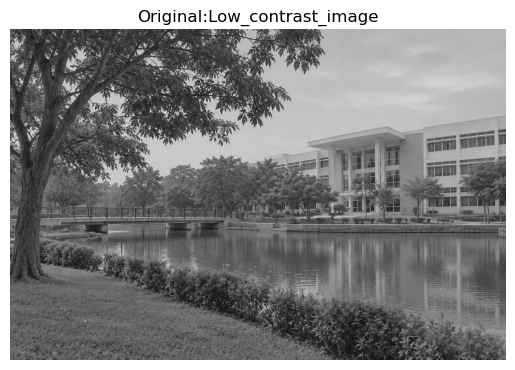

In [33]:
plt.title("Original:Low_contrast_image")
plt.imshow(img,cmap="gray")
plt.axis("off")
plt.show()

In [34]:
histogram,bin_edgs=np.histogram(img.flatten(),bins=256,range=(0,256))

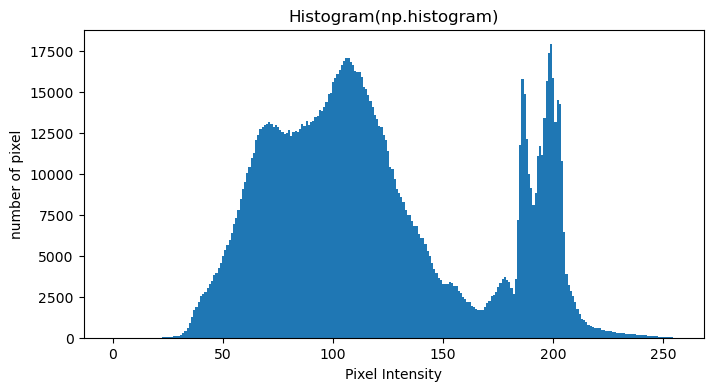

In [35]:
plt.figure(figsize=(8,4))
plt.bar(range(256),histogram,width=1)
plt.title("Histogram(np.histogram)")
plt.xlabel("Pixel Intensity")
plt.ylabel("number of pixel")
plt.show()

x axis - pixel intensity, from blac to white
Y axis - Number of pixel in each intensity
Tall peaks - Many pixel has those intensity value
value concentrated on the left - The image is generally dark value concentraed on the right - The image is generally white

In [36]:
print("Most common intensity value: ",np.argmax(histogram))
print("Number of the pixel at the intensity :",histogram.max())

Most common intensity value:  199
Number of the pixel at the intensity : 17897


compute the histogram using opencv build-in cv2.clacHist function

In [37]:
histogram_cv2=cv2.calcHist([img],[0],None,[256],[0,256])

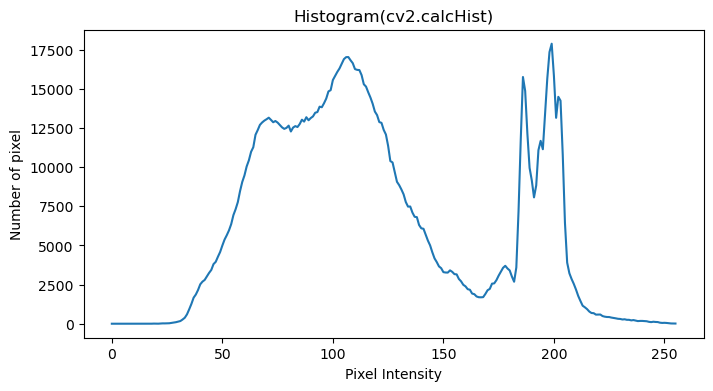

In [38]:
plt.figure(figsize=(8,4))
plt.plot(histogram_cv2)
plt.title("Histogram(cv2.calcHist)")
plt.xlabel("Pixel Intensity")
plt.ylabel("Number of pixel")
plt.show()

In [39]:
Histogram Equalization:manual way
    

SyntaxError: invalid syntax (1931203291.py, line 1)

In [ ]:
cdf=histogram.cumsum()
cdf_normalized=cdf * 255/cdf[-1]

In [ ]:
#mapps each original pixel intensity to its corresponding 
equalized_manual=np.interp(img.flatten(),np.arange(256),cdf_normalized)
equalized_manual=equalized_manual.reshape(img.shape)
equalized_manual=equalized_manual.astype(np.uint8)

In [ ]:
plt.figure(figsize=(10,6))
plt.subplot(1,2,1)
plt.imshow(img,cmap="gray")
plt.title("Original")
plt.axis("off")


plt.subplot(1,2,2)
plt.imshow(equalized_manual,cmap="gray")
plt.title("equalized_manual")
plt.axis("off")

In [ ]:
equalized_cv2=cv2.equalizeHist(img)

In [ ]:
plt.figure(figsize=(10,6))
plt.subplot(1,3,1)
plt.imshow(img,cmap="gray")
plt.title("Original")
plt.axis("off")


plt.subplot(1,3,2)
plt.imshow(equalized_manual,cmap="gray")
plt.title("equalized_manual")
plt.axis("off")


plt.subplot(1,3,3)
plt.imshow(equalized_cv2,cmap="gray")
plt.title("equalized_cv2")
plt.axis("off")

In [ ]:
hist_manual_eq,bin_edges=np.histogram(equalized_manual.flatten(),bins=256,range=(0,256))
hist_cv2_eq,bin_edgs=np.histogram(equalized_cv2.flatten(),bins=256,range=(0,256))

Text(0.5, 1.0, 'Histogram cv2')

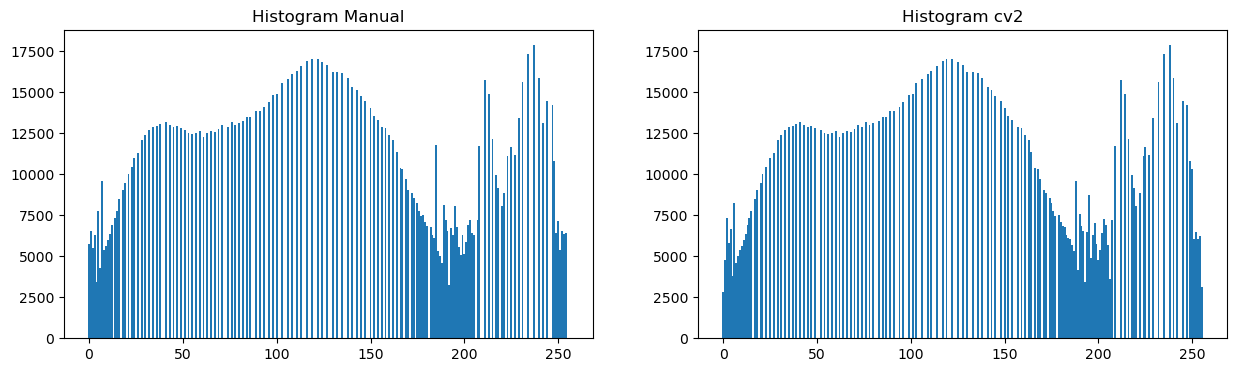

In [41]:
plt.figure(figsize=(15,4))
plt.subplot(1,2,1)
plt.bar(range(256),hist_manual_eq,width=1)
plt.title("Histogram Manual")


plt.subplot(1,2,2)
plt.bar(range(256),hist_cv2_eq,width=1)
plt.title("Histogram cv2")